In [1]:

import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "3"
import torch
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib as plt
from PIL import Image
sys.path.append('../src')
from utils import *
from matplotlib.lines import Line2D
import matplotlib as mpl
import math
import matplotlib.image as mpimg
import scipy.stats as stats
import scipy as sp
from sklearn.decomposition import PCA
from scipy.stats import pearsonr,binom,linregress
from ast import literal_eval
import json
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import gaussian_kde
from matplotlib.patches import Ellipse
import seaborn as sns
pd.set_option('display.max_columns', None)
os.chdir("..")

In [49]:
df = pd.DataFrame()
for mode in ["vision", "imagery"]:
    file_paths = []
    for trials in tqdm([375, 750, 1500, 2250, 3750, 7500, 15000, 27750, 30000], desc="Trials"):
        method = f"braindiffuser_{trials}"
        directory_path = f"output/mental_imagery_paper_b3/{mode}/{method}/subject1_statistics_18.csv"
        current_df = pd.read_csv(directory_path)
        current_df["Sessions"] = trials/750
        df = pd.concat([df, current_df])
df.head()
# df.to_csv(f"output/mental_imagery_paper_b3/brain_diffuser_trial_scaling.csv")


Trials: 100%|██████████| 9/9 [00:00<00:00, 327.68it/s]


,Unnamed: 0,ID,Subject,Method,Mode,Sample Count,Batch Number,Sample Indicator,Strength,Brain Correlation V1,Brain Correlation V2,Brain Correlation V3,Brain Correlation V4,Brain Correlation Early Visual,Brain Correlation Higher Visual,Brain Correlation NSD General,SSIM,Pixel Correlation,CLIP Cosine,CLIP Two-way,AlexNet 1,AlexNet 2,AlexNet 2.1,AlexNet 4,AlexNet 5,AlexNet 6,AlexNet 7,Inception V3,EffNet-B,SwAV,CLIP Two-way 1000,AlexNet 1 1000,AlexNet 2 1000,AlexNet 3 1000,AlexNet 4 1000,AlexNet 5 1000,AlexNet 6 1000,AlexNet 7 1000,Inception V3 1000,AlexNet 3,Sessions
0,0,0,1,braindiffuser_375,vision,NaN,NaN,10,NaN,0.497175,0.496001,0.465564,0.506810,0.470361,0.205092,0.290243,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5
1,1,0,1,braindiffuser_375,vision,NaN,NaN,11,NaN,0.570690,0.497709,0.466511,0.494885,0.511956,0.226671,0.338709,0.756095,-0.075474,0.649282,0.545455,0.909091,0.909091,0.909091,0.909091,1.000000,0.545455,0.636364,0.545455,0.896263,0.511882,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.909091,0.5
2,2,0,1,braindiffuser_375,vision,0.0,NaN,12,NaN,0.443682,0.367536,0.348732,0.388823,0.384400,0.141137,0.248624,0.596185,-0.136774,0.560422,0.363636,0.909091,0.909091,0.909091,0.909091,0.909091,0.727273,0.727273,0.909091,0.965885,0.535200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.909091,0.5
3,3,0,1,braindiffuser_375,vision,1.0,NaN,12,NaN,0.546056,0.465327,0.434931,0.420558,0.468486,0.067718,0.258690,0.608262,0.050011,0.500131,0.363636,1.000000,1.000000,1.000000,0.909091,0.909091,0.909091,0.818182,0.636364,0.968089,0.518482,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.5
4,4,0,1,braindiffuser_375,vision,2.0,NaN,12,NaN,0.294724,0.222975,0.171556,0.337676,0.241262,0.146712,0.181628,0.597984,-0.113804,0.527419,0.363636,0.727273,0.909091,0.909091,0.909091,0.909091,1.000000,0.909091,0.545455,0.921472,0.512271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.909091,0.5


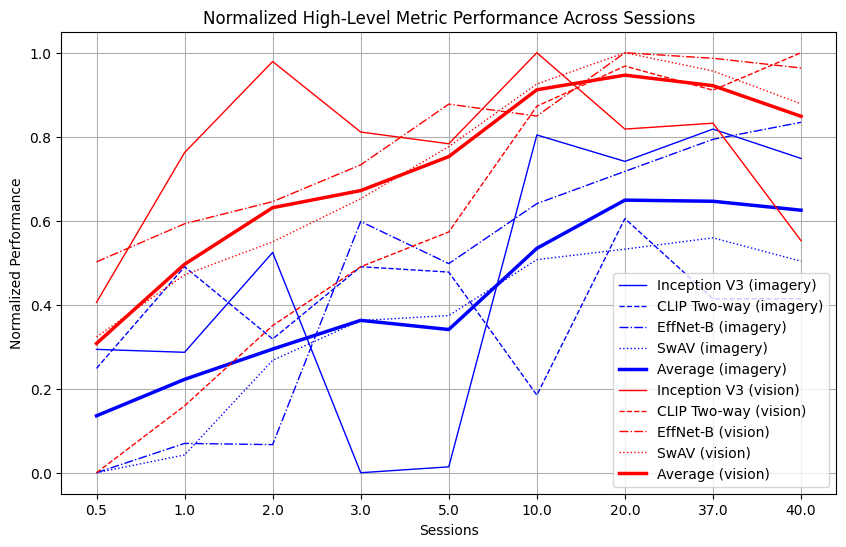

In [40]:
df_final = df[df['Sample Indicator'] == 12]
relevant_metrics = ['Inception V3', 'CLIP Two-way', 'EffNet-B', 'SwAV']
filtered_df = df_final[['Sessions', 'Mode'] + relevant_metrics]
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
for metric in relevant_metrics:
    min_val = avg_df[metric].min()
    max_val = avg_df[metric].max()
    avg_df[metric] = (avg_df[metric] - min_val) / (max_val - min_val)
avg_df['EffNet-B'] = 1 - avg_df['EffNet-B']
avg_df['SwAV'] = 1 - avg_df['SwAV']
avg_df['Average'] = avg_df[relevant_metrics].mean(axis=1)
# print(avg_df)
colors = {'imagery': 'blue', 'vision': 'red'}
linestyles = ['-', '--', '-.',':']
# Plot again with the inverted metrics
plt.figure(figsize=(10, 6))

for mode, df_mode in avg_df.groupby('Mode'):
    color = colors[mode]
    # Plot each metric with a unique linestyle
    for i, metric in enumerate(relevant_metrics):
        plt.plot(df_mode['Sessions'], df_mode[metric], linestyle=linestyles[i], linewidth=1, label=f"{metric} ({mode})", color=color)
    # Plot the average performance with a thicker, bolded line
    plt.plot(df_mode['Sessions'], df_mode['Average'], linewidth=2.5, label=f"Average ({mode})", color=color)

plt.title('Normalized High-Level Metric Performance Across Sessions')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

/tmp/ipykernel_44185/2554139154.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)
/tmp/ipykernel_44185/2554139154.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iter_df['Average'] = iter_df[relevant_metrics].mean(axis=1)
/tmp/ipykernel_44185/2554139154.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the doc

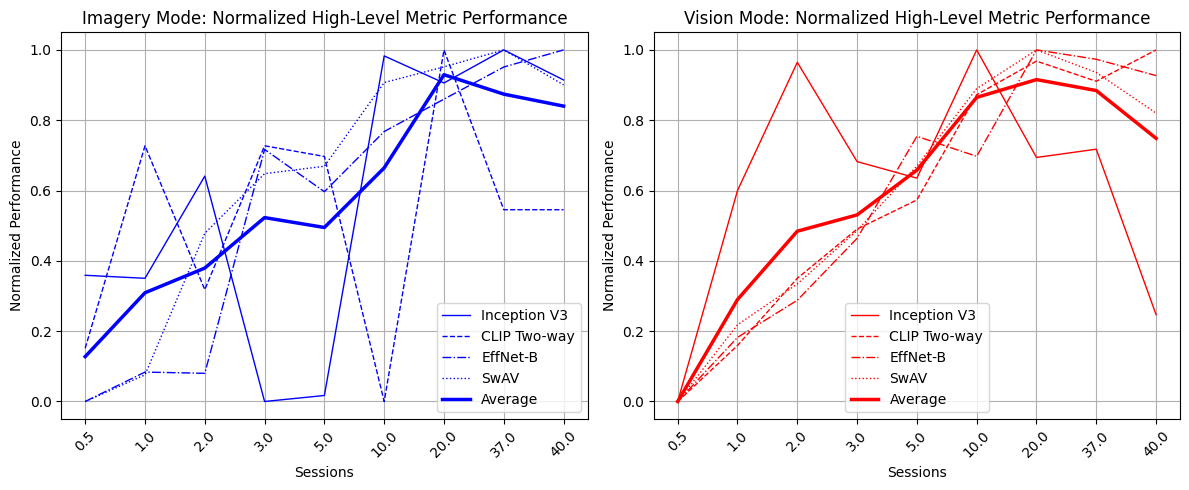

In [48]:
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
avg_df['EffNet-B'] = 1 - avg_df['EffNet-B']
avg_df['SwAV'] = 1 - avg_df['SwAV']
df_imagery = avg_df[avg_df['Mode'] == 'imagery']
df_vision = avg_df[avg_df['Mode'] == 'vision']

# Normalize the metrics in each dataframe between their largest and smallest value independently
for iter_df in [df_imagery, df_vision]:
    for metric in relevant_metrics:
        min_val = iter_df[metric].min()
        max_val = iter_df[metric].max()
        iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)
    # Recalculate the average performance across all metrics after normalization
    iter_df['Average'] = iter_df[relevant_metrics].mean(axis=1)

plt.figure(figsize=(12, 5))
# Imagery Mode Plot
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_imagery['Sessions'], df_imagery[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='blue')
plt.plot(df_imagery['Sessions'], df_imagery['Average'], linewidth=2.5, label='Average', color='blue')
plt.title('Imagery Mode: Normalized High-Level Metric Performance')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

# Vision Mode Plot
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_vision['Sessions'], df_vision[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='red')
plt.plot(df_vision['Sessions'], df_vision['Average'], linewidth=2.5, label='Average', color='red')
plt.title('Vision Mode: Normalized High-Level Metric Performance')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

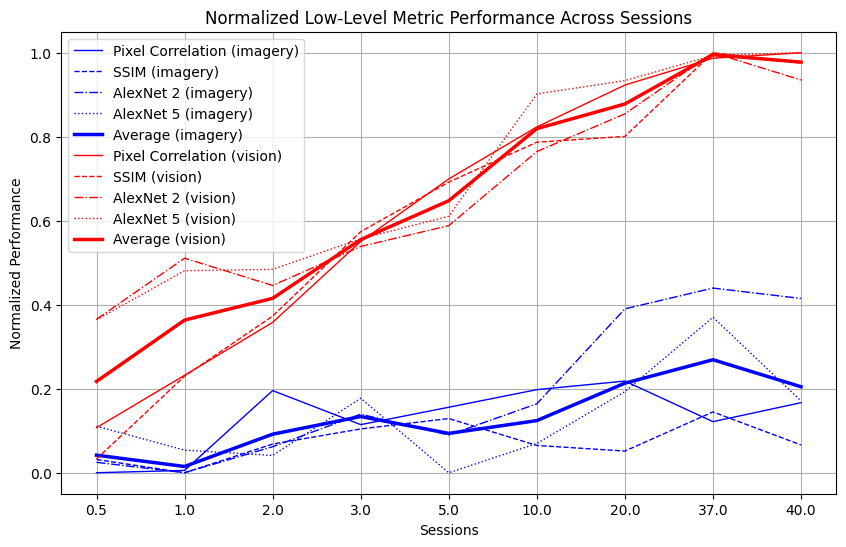

In [50]:
df_final = df[df['Sample Indicator'] == 12]
relevant_metrics = ['Pixel Correlation', 'SSIM', 'AlexNet 2', 'AlexNet 5']
filtered_df = df_final[['Sessions', 'Mode'] + relevant_metrics]
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
for metric in relevant_metrics:
    min_val = avg_df[metric].min()
    max_val = avg_df[metric].max()
    avg_df[metric] = (avg_df[metric] - min_val) / (max_val - min_val)
avg_df['Average'] = avg_df[relevant_metrics].mean(axis=1)
# print(avg_df)
colors = {'imagery': 'blue', 'vision': 'red'}
linestyles = ['-', '--', '-.',':']
# Plot again with the inverted metrics
plt.figure(figsize=(10, 6))

for mode, df_mode in avg_df.groupby('Mode'):
    color = colors[mode]
    # Plot each metric with a unique linestyle
    for i, metric in enumerate(relevant_metrics):
        plt.plot(df_mode['Sessions'], df_mode[metric], linestyle=linestyles[i], linewidth=1, label=f"{metric} ({mode})", color=color)
    # Plot the average performance with a thicker, bolded line
    plt.plot(df_mode['Sessions'], df_mode['Average'], linewidth=2.5, label=f"Average ({mode})", color=color)

plt.title('Normalized Low-Level Metric Performance Across Sessions')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

/tmp/ipykernel_44185/432941476.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)
/tmp/ipykernel_44185/432941476.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iter_df['Average'] = iter_df[relevant_metrics].mean(axis=1)
/tmp/ipykernel_44185/432941476.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

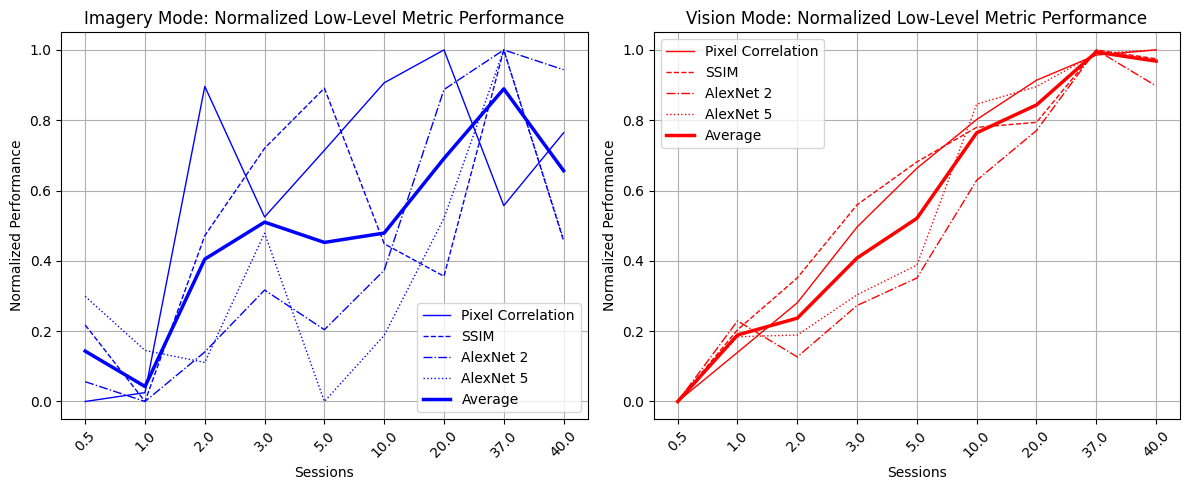

In [51]:
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
df_imagery = avg_df[avg_df['Mode'] == 'imagery']
df_vision = avg_df[avg_df['Mode'] == 'vision']

# Normalize the metrics in each dataframe between their largest and smallest value independently
for iter_df in [df_imagery, df_vision]:
    for metric in relevant_metrics:
        min_val = iter_df[metric].min()
        max_val = iter_df[metric].max()
        iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)
    # Recalculate the average performance across all metrics after normalization
    iter_df['Average'] = iter_df[relevant_metrics].mean(axis=1)

plt.figure(figsize=(12, 5))
# Imagery Mode Plot
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_imagery['Sessions'], df_imagery[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='blue')
plt.plot(df_imagery['Sessions'], df_imagery['Average'], linewidth=2.5, label='Average', color='blue')
plt.title('Imagery Mode: Normalized Low-Level Metric Performance')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

# Vision Mode Plot
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_vision['Sessions'], df_vision[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='red')
plt.plot(df_vision['Sessions'], df_vision['Average'], linewidth=2.5, label='Average', color='red')
plt.title('Vision Mode: Normalized Low-Level Metric Performance')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

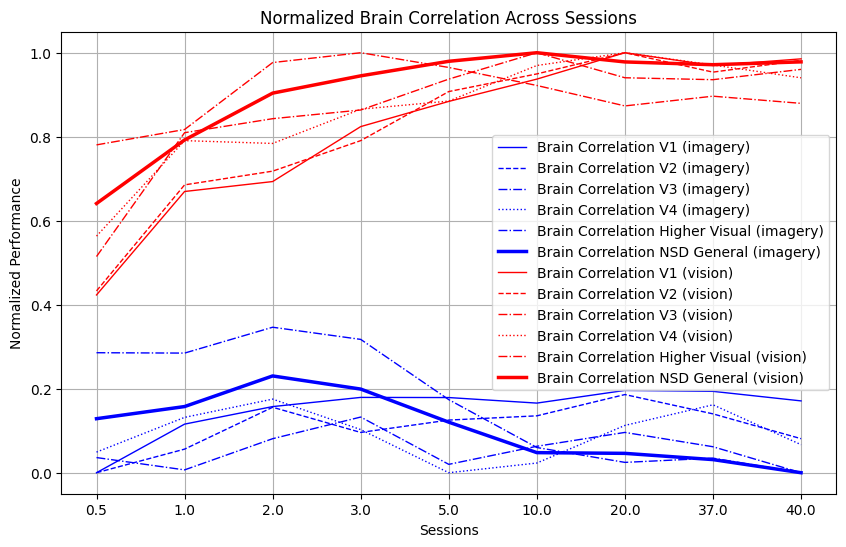

In [52]:
df_final = df[df['Sample Indicator'] == 12]
relevant_metrics = ['Brain Correlation NSD General', 'Brain Correlation V1', 'Brain Correlation V2', 'Brain Correlation V3', 'Brain Correlation V4', 'Brain Correlation Higher Visual']
filtered_df = df_final[['Sessions', 'Mode'] + relevant_metrics]
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
for metric in relevant_metrics:
    min_val = avg_df[metric].min()
    max_val = avg_df[metric].max()
    avg_df[metric] = (avg_df[metric] - min_val) / (max_val - min_val)
# print(avg_df)
colors = {'imagery': 'blue', 'vision': 'red'}
linestyles = ['-', '--', '-.', ':', '-.', '--']
# Plot again with the inverted metrics
plt.figure(figsize=(10, 6))

for mode, df_mode in avg_df.groupby('Mode'):
    color = colors[mode]
    # Plot each metric with a unique linestyle
    for i, metric in enumerate(relevant_metrics[1:]):
        plt.plot(df_mode['Sessions'], df_mode[metric], linestyle=linestyles[i], linewidth=1, label=f"{metric} ({mode})", color=color)
    # Plot the average performance with a thicker, bolded line
    plt.plot(df_mode['Sessions'], df_mode['Brain Correlation NSD General'], linewidth=2.5, label=f"Brain Correlation NSD General ({mode})", color=color)

plt.title('Normalized Brain Correlation Across Sessions')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.legend(loc='center right')
plt.grid(True)
plt.show()

/tmp/ipykernel_44185/853471858.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)


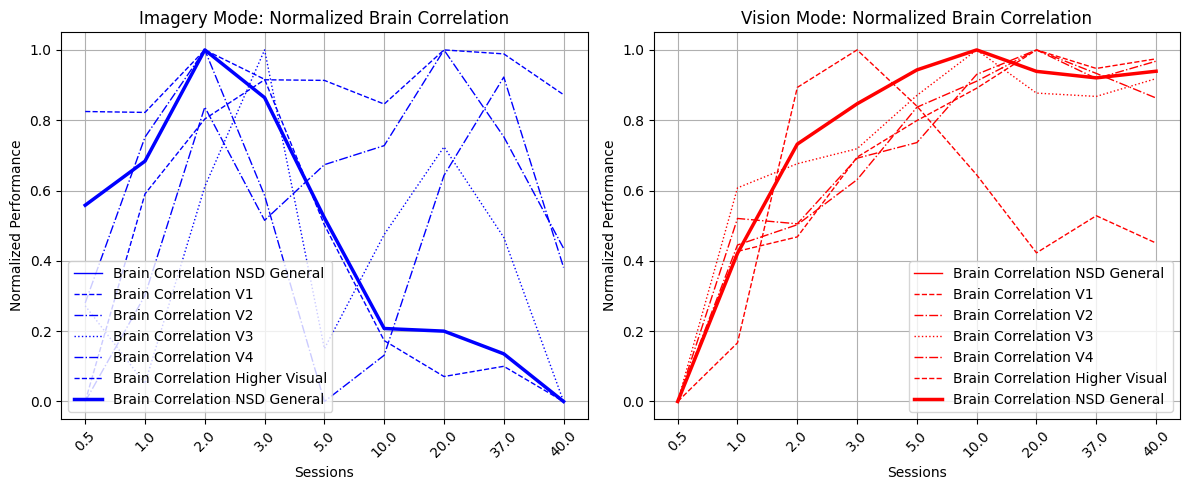

In [55]:
avg_df = filtered_df.groupby(['Sessions', 'Mode']).mean().reset_index()
avg_df['Sessions'] = avg_df['Sessions'].astype(str)
df_imagery = avg_df[avg_df['Mode'] == 'imagery']
df_vision = avg_df[avg_df['Mode'] == 'vision']

# Normalize the metrics in each dataframe between their largest and smallest value independently
for iter_df in [df_imagery, df_vision]:
    for metric in relevant_metrics:
        min_val = iter_df[metric].min()
        max_val = iter_df[metric].max()
        iter_df[metric] = (iter_df[metric] - min_val) / (max_val - min_val)

plt.figure(figsize=(12, 5))
# Imagery Mode Plot
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_imagery['Sessions'], df_imagery[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='blue')
plt.plot(df_imagery['Sessions'], df_imagery['Brain Correlation NSD General'], linewidth=2.5, label=f"Brain Correlation NSD General", color='blue')
plt.title('Imagery Mode: Normalized Brain Correlation')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

# Vision Mode Plot
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
for i, metric in enumerate(relevant_metrics):
    plt.plot(df_vision['Sessions'], df_vision[metric], linestyle=linestyles[i], linewidth=1, label=metric, color='red')
plt.plot(df_vision['Sessions'], df_vision['Brain Correlation NSD General'], linewidth=2.5, label=f"Brain Correlation NSD General", color='red')
plt.title('Vision Mode: Normalized Brain Correlation')
plt.xlabel('Sessions')
plt.ylabel('Normalized Performance')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()